# Terrain-aware MDV `RATE_HYBRID` → reference-grid NetCDF

Converts **one** polar MDV rainfall-rate volume to a Cartesian rainfall-rate product (**mm/h**), using the lowest elevation whose beam center remains at least `MIN_CLEARANCE_M` above terrain along the entire radial. Output matches the **horizontal grid coordinates and dimensions** of a supplied reference NetCDF.

**Prototype limitations:** coarse 0.1° DEM (~11 km), beam-center rather than partial-beam blockage, 4/3-Earth propagation, nearest-gate sampling, no attenuation/gauge correction, and no rainfall accumulation. Missing radar values must be distinguished from true zero rainfall; the notebook prints a zero-value diagnostic. **Do not treat this as validated operational QPE.**

In [1]:
# Run once if packages are missing:
# %pip install arm_pyart numpy scipy xarray netCDF4 matplotlib pyproj

In [ ]:
from pathlib import Path
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from scipy.ndimage import map_coordinates
from pyproj import Geod
from pyart.io.mdv_common import MdvFile

MDV_FILE = Path('/Volumes/Rain/LiCie/projDir/data/mdv/radarPolar/derived/sur/20190206/070402.mdv')
REFERENCE_NC = Path('../../data/example_grids/eg_radar_grid.nc')  # CHANGE THIS
OUTPUT_NC = Path('rate_hybrid_terrain_aware.nc')

FIELD = 'RATE_HYBRID'
MIN_CLEARANCE_M = 300.0
NEAR_RADAR_IGNORE_M = 1000.0  # avoid zero-range DEM/radar-height mismatch
MAX_RADAR_RANGE_M = 250_000.0
MAX_GATE_OFFSET_M = 1_000.0   # nearest range-gate tolerance
K_EARTH = 4.0 / 3.0
EARTH_RADIUS_M = 6_371_000.0
# Set True only if you have verified that zero means missing in THIS field.
MASK_ZERO_RAIN = False

for p in (MDV_FILE, REFERENCE_NC):
    if not p.is_file():
        raise FileNotFoundError(f'Missing input: {p}')


## You are using the Python ARM Radar Toolkit (Py-ART), an open source
## library for working with weather radar data. Py-ART is partly supported
## by the U.S. Department of Energy Office of Science as part of
## the Atmospheric Radiation Measurement (ARM) User Facility.
##
## If you use this software to prepare a publication, please cite:
##
##     JJ Helmus and SM Collis, JORS 2016, doi: 10.5334/jors.119



## 1. Read radar and check field layout

In [3]:
mdv = MdvFile(str(MDV_FILE))
field_index = next(i for i, h in enumerate(mdv.field_headers)
                   if h['field_name'].strip() == FIELD)
h = mdv.field_headers[field_index]
v = mdv.vlevel_headers[field_index]
nx, ny, nz = (int(h[k]) for k in ('nx','ny','nz'))
elevations = np.asarray(v['level'][:nz], dtype=float)
radar_lat = float(mdv.master_header['sensor_lat'])
radar_lon = float(mdv.master_header['sensor_lon'])
radar_alt_m = float(mdv.master_header['sensor_alt']) * 1000.0
ranges_m = (float(h['grid_minx']) + np.arange(nx) * float(h['grid_dx'])) * 1000
azimuths = (float(h['grid_miny']) + np.arange(ny) * float(h['grid_dy'])) % 360
if not np.all(np.diff(elevations) > 0):
    raise ValueError('Elevation angles not strictly ascending; inspect vlevel header')
if not np.all(np.diff(ranges_m) > 0):
    raise ValueError('Range gates not ascending')
if abs(float(h['grid_dy']) - 1.0) > 1e-3 or ny != 360:
    raise ValueError('This prototype assumes 360 azimuths at 1-degree spacing')
raw = np.ma.asarray(mdv.read_a_field(field_index))
if raw.shape == (nz,ny,nx):
    pass
elif raw.shape == (ny,nx,nz):
    raw = np.moveaxis(raw,-1,0)
elif raw.shape == (nx,ny,nz):
    raw = np.transpose(raw,(2,1,0))
else:
    raise ValueError(f'Unexpected field shape {raw.shape}, expected {(nz,ny,nx)}')
rain = np.ma.filled(raw,np.nan).astype(np.float32)
rain[~np.isfinite(rain) | (rain < 0)] = np.nan
if MASK_ZERO_RAIN:
    rain[rain == 0] = np.nan
print('Radar:',radar_lat,radar_lon,'altitude m:',radar_alt_m)
print('Rain shape:',rain.shape,'units:',h['units'])
print('Elevations:',elevations)
print('Finite:',np.isfinite(rain).sum(),'zero:',np.count_nonzero(rain==0),
      'positive:',np.count_nonzero(rain>0))
print('Finite min/max:',np.nanmin(rain),np.nanmax(rain))
print('Header missing/bad:',h['missing_data_value'],h['bad_data_value'])
print('WARNING: Header missing/bad are both zero. Inspect the zero count and data before interpreting zero as no rain.')

Radar: -2.158076047897339 30.112340927124023 altitude m: 1616.0000562667847
Rain shape: (11, 360, 1042) units: mm/hr
Elevations: [ 0.5         1.48000002  2.5         3.5         4.5         6.
  8.         11.         15.         22.         32.        ]
Finite: 441610 zero: 0 positive: 441610
Finite min/max: 0.099999994 250.0
Header missing/bad: 0.0 0.0


## 2. Read decoded terrain and validate the radar neighborhood

In [10]:

import numpy as np
import xarray as xr
from scipy.spatial import cKDTree
from pyproj import Transformer

ELEVATION_NC = "../../data/constants/elev.nc"

ds_dem = xr.open_dataset(ELEVATION_NC)

terrain = ds_dem["elevation"].values.astype(np.float32)
dem_lat = ds_dem["lat"].values
dem_lon = ds_dem["lon"].values

# Ensure all arrays have the same shape
assert terrain.shape == dem_lat.shape == dem_lon.shape

# Convert geographic coordinates to projected metres
# UTM Zone 36S, suitable for the Rwanda radar region
transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:32736",
    always_xy=True
)

dem_x, dem_y = transformer.transform(dem_lon, dem_lat)

valid = (
    np.isfinite(terrain)
    & np.isfinite(dem_x)
    & np.isfinite(dem_y)
)

dem_points = np.column_stack([
    dem_x[valid],
    dem_y[valid]
])

dem_values = terrain[valid]

tree_dem = cKDTree(dem_points)


def sample_terrain(lat, lon):
    """Nearest-neighbour terrain elevation in metres."""

    lat, lon = np.broadcast_arrays(lat, lon)

    x, y = transformer.transform(lon, lat)

    points = np.column_stack([
        np.asarray(x).ravel(),
        np.asarray(y).ravel()
    ])

    distance, indices = tree_dem.query(
        points,
        distance_upper_bound=1500.0
    )

    values = np.full(
        len(points),
        np.nan,
        dtype=np.float32
    )

    good = np.isfinite(distance)
    values[good] = dem_values[indices[good]]

    return values.reshape(lat.shape)


print("Terrain loaded successfully")
print("Elevation range:",
      np.nanmin(terrain),
      np.nanmax(terrain))


Terrain loaded successfully
Elevation range: 767.0 4349.8833


## 3. Terrain obstruction along each radial

Exclude the first 1 km from blockage assessment to avoid the zero-range radar-site DEM mismatch. This is an approximate workaround; inspect the diagnostics and use a finer DEM for scientific analysis.


In [14]:

import numpy as np
from pyproj import Geod

# ============================================================
# 1. COMPUTE RADAR GATE COORDINATES
# ============================================================

geod = Geod(ellps="WGS84")

az_grid = np.broadcast_to(
    azimuths[:, None], (ny, nx)
)

range_grid = np.broadcast_to(
    ranges_m[None, :], (ny, nx)
)

radial_lon, radial_lat, _ = geod.fwd(
    np.full((ny, nx), radar_lon),
    np.full((ny, nx), radar_lat),
    az_grid,
    range_grid
)

# IMPORTANT:
# sample_dem expects (latitude, longitude), not (longitude, latitude).
terrain_radial = sample_terrain(radial_lat, radial_lon)

# ============================================================
# 2. CHECK DEM SAMPLING
# ============================================================

print("=" * 65)
print("DEM SAMPLING DIAGNOSTICS")
print("=" * 65)

print("Radar latitude:", radar_lat)
print("Radar longitude:", radar_lon)

print(
    "Radial latitude range:",
    np.nanmin(radial_lat),
    np.nanmax(radial_lat)
)

print(
    "Radial longitude range:",
    np.nanmin(radial_lon),
    np.nanmax(radial_lon)
)

print("First gate ranges (m):", ranges_m[:8])
print("First-gate terrain (m):", terrain_radial[0, :8])

# print(
#     "Radar DEM vs instrument altitude (m):",
#     radar_dem, radar_alt_m
# )

valid_fraction = np.isfinite(terrain_radial).mean()

print(
    "DEM valid fraction along rays:",
    f"{valid_fraction:.2%}"
)

if valid_fraction == 0:
    raise ValueError(
        "No valid DEM samples along radar rays. "
        "Check sample_dem argument order, DEM coverage, "
        "coordinate transformation and search radius."
    )

print(
    "Terrain elevation range (m):",
    np.nanmin(terrain_radial),
    np.nanmax(terrain_radial)
)

# ============================================================
# 3. RADAR BEAM HEIGHT
# ============================================================

def beam_center_asl(range_m, elevation_deg):
    """
    Approximate radar beam-center height above sea level.

    Uses the standard 4/3-Earth-radius approximation.
    """
    elev = np.deg2rad(elevation_deg)
    re = K_EARTH * EARTH_RADIUS_M

    return (
        radar_alt_m
        + np.sqrt(
            range_m**2
            + re**2
            + 2 * range_m * re * np.sin(elev)
        )
        - re
    )


# ============================================================
# 4. TERRAIN-AWARE BEAM CLEARANCE
# ============================================================

usable = np.zeros(
    (nz, ny, nx), dtype=bool
)

height_agl = np.full(
    (nz, ny, nx),
    np.nan,
    dtype=np.float32
)

near = ranges_m < NEAR_RADAR_IGNORE_M

for k, elev in enumerate(elevations):

    beam_asl = beam_center_asl(
        ranges_m, elev
    )[None, :]

    height = beam_asl - terrain_radial

    height_agl[k] = height

    # Beam center must clear terrain by at least
    # MIN_CLEARANCE_M.
    clear = (
        np.isfinite(height)
        & (height >= MIN_CLEARANCE_M)
    )

    # Ignore the immediate radar-site region.
    # This is an approximation to avoid DEM/radar
    # altitude mismatch invalidating all radials.
    clear[:, near] = True

    # Once blocked, the radial remains blocked.
    usable[k] = np.logical_and.accumulate(
        clear, axis=1
    )

    # Do not produce rainfall inside ignored region.
    usable[k, :, near] = False

    print(
        f"{elev:5.2f} degrees: "
        f"usable gates {100 * usable[k].mean():5.1f}%; "
        f"clear beyond exclusion "
        f"{100 * clear[:, ~near].mean():5.1f}%"
    )


# ============================================================
# 5. CHECK USABLE RADAR COVERAGE
# ============================================================

if not np.any(usable):
    raise ValueError(
        "All sweeps are blocked or lack DEM coverage. "
        "Check terrain sampling, DEM extent, "
        "radar altitude and clearance threshold."
    )


# ============================================================
# 6. SELECT LOWEST USABLE ELEVATION
# ============================================================

selected = np.full(
    (ny, nx),
    np.nan,
    dtype=np.float32
)

selected_elev = np.full(
    (ny, nx),
    np.nan,
    dtype=np.float32
)

selected_agl = np.full(
    (ny, nx),
    np.nan,
    dtype=np.float32
)

# Elevations are assumed ordered lowest to highest.
for k, elev in enumerate(elevations):

    ok = (
        usable[k]
        & np.isfinite(rain[k])
        & ~np.isfinite(selected)
    )

    selected[ok] = rain[k][ok]
    selected_elev[ok] = elev
    selected_agl[ok] = height_agl[k][ok]


# ============================================================
# 7. FINAL DIAGNOSTICS
# ============================================================

print("\n" + "=" * 65)
print("TERRAIN-AWARE RAINFALL SELECTION")
print("=" * 65)

n_valid = np.isfinite(selected).sum()

print(
    "Usable rainfall gates:",
    n_valid, "/", selected.size
)

print(
    "Usable rainfall fraction:",
    f"{100 * n_valid / selected.size:.2f}%"
)

if n_valid > 0:
    print(
        "Rainfall range (mm/h):",
        np.nanmin(selected),
        np.nanmax(selected)
    )

    print("\nSelected elevation distribution:")

    for elev in elevations:
        count = np.sum(
            np.isfinite(selected_elev)
            & np.isclose(selected_elev, elev)
        )

        print(
            f"{elev:5.2f} degrees: "
            f"{count:8d} gates"
        )


DEM SAMPLING DIAGNOSTICS
Radar latitude: -2.158076047897339
Radar longitude: 30.112340927124023
Radial latitude range: -4.415912169922696 0.0998272816991877
Radial longitude range: 27.86796310166199 32.356718752586055
First gate ranges (m): [   0.          239.8339659   479.6679318   719.50189769  959.33586359
 1199.16982949 1439.00379539 1678.83776128]
First-gate terrain (m): [1599.0452 1599.0452 1599.0452 1479.4138 1479.4138 1479.4138 1479.4138
 1437.8861]
DEM valid fraction along rays: 88.37%
Terrain elevation range (m): 767.0 4349.8833
 0.50 degrees: usable gates   0.0%; clear beyond exclusion  82.4%
 1.48 degrees: usable gates   0.0%; clear beyond exclusion  87.0%
 2.50 degrees: usable gates   0.0%; clear beyond exclusion  87.7%
 3.50 degrees: usable gates   0.0%; clear beyond exclusion  87.9%
 4.50 degrees: usable gates   0.0%; clear beyond exclusion  88.0%
 6.00 degrees: usable gates   9.6%; clear beyond exclusion  88.1%
 8.00 degrees: usable gates  32.5%; clear beyond exclusion

## 4. Read the reference NetCDF horizontal grid

Supports 1D `lat`/`lon` (or `latitude`/`longitude`) and 2D geographic coordinate arrays. **Projected x/y-only grids require an explicit CRS and are not automatically guessed.**

In [15]:
ref=xr.open_dataset(REFERENCE_NC)
print(ref)
lat_name=next((s for s in ('lat','latitude') if s in ref.variables),None)
lon_name=next((s for s in ('lon','longitude') if s in ref.variables),None)
if lat_name is None or lon_name is None:
    raise ValueError('Reference must contain lat/lon coordinate variables. Upload it to adapt projected grids.')
lat_da,lon_da=ref[lat_name],ref[lon_name]
if lat_da.ndim==1 and lon_da.ndim==1:
    target_lon,target_lat=np.meshgrid(lon_da.values,lat_da.values)
    dims=(lat_da.dims[0],lon_da.dims[0])
    out_coords={dims[0]:ref[dims[0]],dims[1]:ref[dims[1]]}
elif lat_da.ndim==2 and lon_da.ndim==2 and lat_da.dims==lon_da.dims:
    target_lat,target_lon=lat_da.values,lon_da.values
    dims=lat_da.dims
    out_coords={d:ref[d] if d in ref.variables else np.arange(ref.sizes[d]) for d in dims}
    out_coords[lat_name]=lat_da
    out_coords[lon_name]=lon_da
else:
    raise ValueError('Unsupported reference lat/lon layout; inspect the printed dataset')
if target_lat.shape!=target_lon.shape:
    raise ValueError('Reference latitude/longitude shape mismatch')
print('Output dimensions:',dims,'shape:',target_lat.shape)

<xarray.Dataset> Size: 4MB
Dimensions:      (y: 396, x: 396)
Coordinates:
  * y            (y) float64 3kB -1.98e+05 -1.97e+05 ... 1.96e+05 1.97e+05
  * x            (x) float64 3kB -1.98e+05 -1.97e+05 ... 1.96e+05 1.97e+05
    lon          (y, x) float64 1MB ...
    lat          (y, x) float64 1MB ...
    central_lon  float64 8B ...
    central_lat  float64 8B ...
    time         datetime64[ns] 8B ...
Data variables:
    qpe          (y, x) float64 1MB ...
Output dimensions: ('y', 'x') shape: (396, 396)


## 5. Sample selected polar rainfall on the target grid

Inverse-distance weighted interpolation (8 neighbours, maximum 4 km). Diagnostics use nearest valid gate. This can smooth radial striping but may bridge narrow blocked sectors.


In [16]:
# Section 5: IDW interpolation from selected polar rainfall to target grid
from scipy.spatial import cKDTree

# Geodesic gate positions were computed in Section 3.
# Use local azimuthal-equidistant coordinates centred on the radar so
# Euclidean distances in the KD-tree are measured approximately in metres.
from pyproj import CRS, Transformer
local_crs = CRS.from_proj4(
    f"+proj=aeqd +lat_0={radar_lat} +lon_0={radar_lon} "
    "+datum=WGS84 +units=m +no_defs"
)
to_local = Transformer.from_crs('EPSG:4326', local_crs, always_xy=True)
sx, sy = to_local.transform(radial_lon, radial_lat)
tx, ty = to_local.transform(target_lon, target_lat)

# Only use terrain-cleared gates with valid rainfall values.
source_valid = np.isfinite(selected) & np.isfinite(sx) & np.isfinite(sy)
source_xy = np.column_stack((sx[source_valid], sy[source_valid]))
if len(source_xy) == 0:
    raise ValueError('No usable polar rainfall gates')
tree = cKDTree(source_xy)
source_rain = selected[source_valid]
source_elev = selected_elev[source_valid]
source_agl = selected_agl[source_valid]

# Query eight neighbours within 4 km; do not extrapolate outside coverage.
K = 8
MAX_IDW_DISTANCE_M = 4000.0
query_valid = np.isfinite(tx) & np.isfinite(ty)
query_xy = np.column_stack((tx[query_valid], ty[query_valid]))
distances, indices = tree.query(query_xy, k=K,
                               distance_upper_bound=MAX_IDW_DISTANCE_M)
if distances.ndim == 1:
    distances = distances[:, None]
    indices = indices[:, None]
neighbor_ok = np.isfinite(distances) & (indices < len(source_rain))
safe_idx = np.where(neighbor_ok, indices, 0)
weights = np.where(neighbor_ok, 1.0 / np.maximum(distances, 100.0)**2, 0.0)
weight_sum = weights.sum(axis=1)

# Avoid filling targets beyond nominal radar range, including the near-radar exclusion.
_, _, target_range_m = geod.inv(
    np.full(target_lon.shape, radar_lon),
    np.full(target_lat.shape, radar_lat), target_lon, target_lat
)
allowed = query_valid.copy()
allowed[query_valid] = (
    (target_range_m[query_valid] <= min(MAX_RADAR_RANGE_M, ranges_m[-1])) &
    (target_range_m[query_valid] >= NEAR_RADAR_IGNORE_M)
)
flat_rain = np.full(target_lon.size, np.nan, dtype=np.float32)
flat_elev = np.full(target_lon.size, np.nan, dtype=np.float32)
flat_agl = np.full(target_lon.size, np.nan, dtype=np.float32)

# IDW rainfall; diagnostic fields retain nearest-gate values.
local_rain = np.full(len(query_xy), np.nan, dtype=np.float32)
local_elev = np.full(len(query_xy), np.nan, dtype=np.float32)
local_agl = np.full(len(query_xy), np.nan, dtype=np.float32)
good = weight_sum > 0
local_rain[good] = (
    np.sum(weights[good] * source_rain[safe_idx[good]], axis=1)
    / weight_sum[good]
)
nearest_good = neighbor_ok[:, 0]
local_elev[nearest_good] = source_elev[safe_idx[nearest_good, 0]]
local_agl[nearest_good] = source_agl[safe_idx[nearest_good, 0]]
flat_rain[query_valid.ravel()] = local_rain
flat_elev[query_valid.ravel()] = local_elev
flat_agl[query_valid.ravel()] = local_agl
flat_rain[~allowed.ravel()] = np.nan
flat_elev[~allowed.ravel()] = np.nan
flat_agl[~allowed.ravel()] = np.nan
out_rain = flat_rain.reshape(target_lon.shape)
out_elev = flat_elev.reshape(target_lon.shape)
out_agl = flat_agl.reshape(target_lon.shape)
print('Valid output pixels:', np.isfinite(out_rain).sum(), '/', out_rain.size)
print('Output min/max mm/h:',
      np.nanmin(out_rain) if np.isfinite(out_rain).any() else None,
      np.nanmax(out_rain) if np.isfinite(out_rain).any() else None)


Valid output pixels: 80437 / 156816
Output min/max mm/h: 0.099999994 4.680812


## 6. Save NetCDF (mm/h)

In [17]:
out=xr.Dataset(
    data_vars={
      'rain_rate':(dims,out_rain,{'units':'mm/h','long_name':'Terrain-aware radar rainfall rate'}),
      'selected_elevation':(dims,out_elev,{'units':'degree','long_name':'Selected radar elevation angle'}),
      'beam_height_agl':(dims,out_agl,{'units':'m','long_name':'Selected beam center height above terrain'}),
      'radar_coverage':(dims,np.isfinite(out_rain).astype('uint8'),
                        {'long_name':'1 where terrain-aware rainfall estimate is available','flag_values':[0,1]})
    },coords=out_coords,
    attrs={'source_mdv':str(MDV_FILE),'radar_field':FIELD,
           'method':'lowest clear beam center along complete radar radial; IDW 8 neighbours up to 4 km',
           'minimum_clearance_m':MIN_CLEARANCE_M,
           'terrain_source':str(TERRAIN_NPZ),
           'limitations':'Coarse terrain; no fractional beam blockage; no gauge correction; no temporal accumulation'})
# Preserve time as metadata; no time dimension is added to the reference horizontal grid.
from datetime import datetime,timezone
out.attrs['radar_time_utc']=datetime.fromtimestamp(
    int(mdv.master_header['time_centroid']),timezone.utc).isoformat()
OUTPUT_NC.parent.mkdir(parents=True,exist_ok=True)
out.to_netcdf(OUTPUT_NC,encoding={k:{'zlib':True,'complevel':4} for k in out.data_vars})
print('Saved:',OUTPUT_NC.resolve())
print(out)
ref.close()

Saved: /Users/matthewwright/git/SEWAA-forecasts-Rwanda_radar/SEWAA-forecasts/code/ifs+cgan_radar/rate_hybrid_terrain_aware.nc
<xarray.Dataset> Size: 5MB
Dimensions:             (y: 396, x: 396)
Coordinates:
  * y                   (y) float64 3kB -1.98e+05 -1.97e+05 ... 1.97e+05
  * x                   (x) float64 3kB -1.98e+05 -1.97e+05 ... 1.97e+05
    lon                 (y, x) float64 1MB 28.33 28.34 28.35 ... 31.87 31.88
    lat                 (y, x) float64 1MB -3.947 -3.947 ... -0.3757 -0.3757
    central_lon         float64 8B 30.11
    central_lat         float64 8B -2.158
    time                datetime64[ns] 8B 2026-06-26T12:00:00
Data variables:
    rain_rate           (y, x) float32 627kB nan nan nan nan ... nan nan nan nan
    selected_elevation  (y, x) float32 627kB nan nan nan nan ... nan nan nan nan
    beam_height_agl     (y, x) float32 627kB nan nan nan nan ... nan nan nan nan
    radar_coverage      (y, x) uint8 157kB 0 0 0 0 0 0 0 0 0 ... 0 0 0 0 0 0 0 0
Attribut

## 7. Diagnostic plots

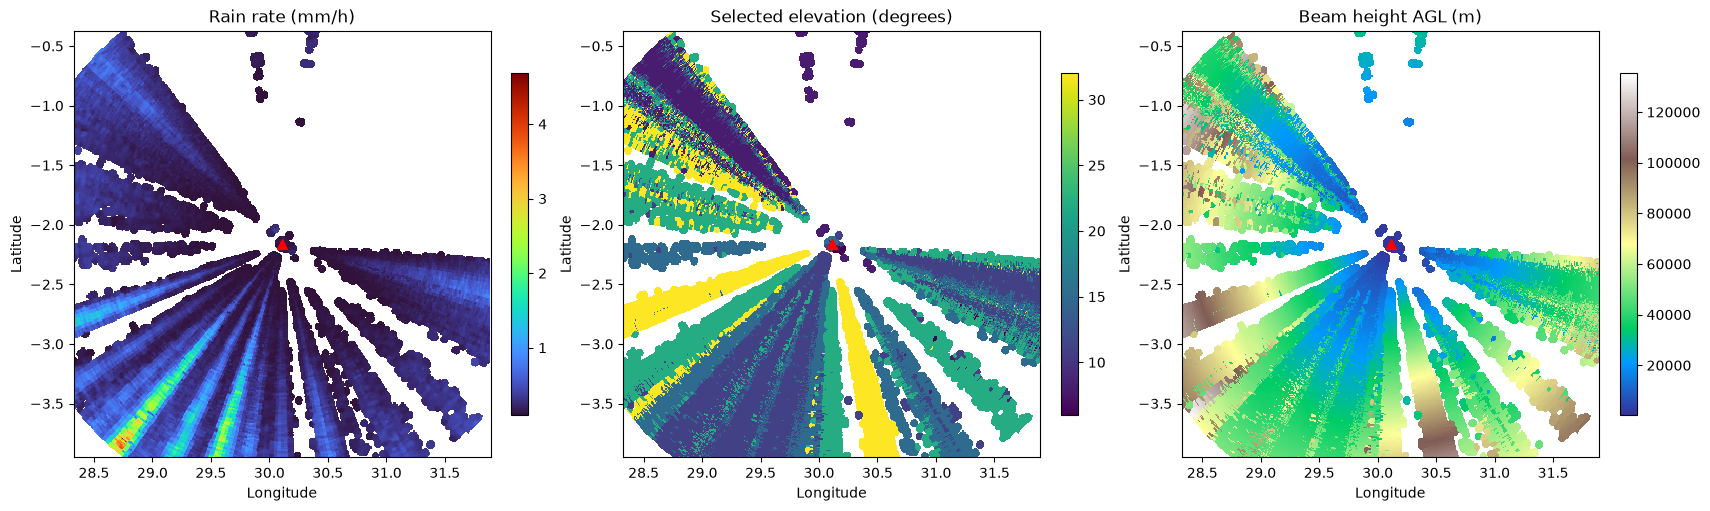

Selected elevation distribution:
 6.00 deg: 161 pixels
 8.00 deg: 7299 pixels
11.00 deg: 19317 pixels
15.00 deg: 17148 pixels
22.00 deg: 23856 pixels
32.00 deg: 12656 pixels
IMPORTANT: inspect suspicious zero rainfall, terrain blockage sectors and DEM coverage.


In [18]:
fig,axes=plt.subplots(1,3,figsize=(17,5),constrained_layout=True)
for ax,values,title,cmap in zip(
    axes,(out_rain,out_elev,out_agl),
    ('Rain rate (mm/h)','Selected elevation (degrees)','Beam height AGL (m)'),
    ('turbo','viridis','terrain')):
    im=ax.pcolormesh(target_lon,target_lat,values,shading='auto',cmap=cmap)
    ax.plot(radar_lon,radar_lat,'r^',markersize=7)
    ax.set_title(title);ax.set_xlabel('Longitude');ax.set_ylabel('Latitude')
    fig.colorbar(im,ax=ax,shrink=0.8)
plt.show()
print('Selected elevation distribution:')
for elev in elevations:
    count=np.count_nonzero(np.isclose(out_elev,elev,atol=0.01))
    if count: print(f'{elev:5.2f} deg: {count} pixels')
print('IMPORTANT: inspect suspicious zero rainfall, terrain blockage sectors and DEM coverage.')